# M101 — SPHEREx DR1 All-Sky Cube de 102 canales

Consulta con **Astroquery** a IRSA y lectura FITS con **Astropy**. Se usan las coordenadas actuales de M101: RA = 210.80227°, Dec = 54.34895° (ICRS).

Se conserva la tesela original que contiene M101, con sus 102 canales. No representa todo el cielo en un único archivo. La muestra solicitada contiene **seis** canales: 1, 20, 40, 60, 80 y 102 (numeración desde 1). Se guardan tanto las imágenes de brillo como sus coordenadas espectrales; también se extrae una tabla del píxel de M101.

Fuentes: [acceso y colección spherex_dr1_cube](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-access/) y [formato IMAGE, NHITS, FLAGS y SPECTRAL_CHANNELS](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-products/). El producto oficial ya tiene sustraída la luz zodiacal; FLAGS contiene bits de calidad. No se modifican ni enmascaran los valores originales.


In [2]:
# Si faltan dependencias, descomenta y ejecuta en este kernel:
# %pip install -U astroquery astropy numpy matplotlib
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from IPython.display import display

COORD = SkyCoord(ra=210.80227*u.deg, dec=54.34895*u.deg, frame="icrs")
CANALES = np.array([1, 20, 40, 60, 80, 102])
INDICES = CANALES - 1
COLUMNAS = {"centro": None, "inferior": None, "superior": None, "ancho": None}
UNIDAD_SIN_METADATA = u.um  # Convención del producto; se priorizan siempre las unidades FITS.


## 1. Consultar las teselas que intersectan M101

La consulta devuelve metadatos y URL; la carga de imágenes ocurre en la siguiente sección. Si la posición está cerca de un borde puede haber varias teselas. Se elige una que contenga el píxel de M101 dentro de la imagen y se muestra su URL para trazabilidad. Esto no es un mosaico de toda la galaxia.


In [3]:
results = Irsa.query_sia(pos=(COORD, 1*u.arcsec), collection=["spherex_dr1_cube"])
if not len(results):
    raise RuntimeError("No se encontraron teselas: consulta el plan de acción al final.")
urls = sorted({str(v).strip() for v in results["access_url"]
               if not np.ma.is_masked(v) and str(v).strip()})
if not urls:
    raise RuntimeError("La respuesta no contiene URLs utilizables.")
print(f"Teselas candidatas: {len(urls)}")
display(results)


Teselas candidatas: 1


s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,s_resolution,em_min,em_max,em_res_power,proposal_title,access_url,access_format,access_estsize,t_exptime,s_region,obs_collection,obs_intent,algorithm_name,facility_keywords,instrument_keywords,environment_photometric,proposal_id,proposal_pi,proposal_project,target_name,target_type,target_standard,target_moving,target_keywords,obs_release_date,s_xel1,s_xel2,s_pixel_scale,position_timedependent,t_min,t_max,t_resolution,t_xel,obs_publisher_did,s_fov,em_xel,pol_states,pol_xel,cloud_access,o_ucd,upload_row_id
deg,deg,,,,,,,,,arcsec,m,m,,,,,kbyte,s,deg,,,,,,,,,,,,,,,,,,arcsec,,d,d,s,,,deg,,,,,,
float64,float64,object,object,object,int16,object,object,object,object,float64,float64,float64,float64,object,object,object,int64,float64,object,object,object,object,object,object,bool,object,object,object,object,object,bool,bool,object,object,int64,int64,float64,bool,float64,float64,float64,int64,object,float64,int64,object,int64,object,object,int64
211.875,54.34091230386124,SPHEREx,SPHEREx,science,3,cube,SPHEREx,Infrared,hips5_cube-hips_20261026,6.440000,7.455e-07,5.0096e-06,--,SPHEREx All-Sky Cube,https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits,image/fits,320910,--,POLYGON ICRS 211.30434782608694 55.87335043525198 213.75 54.340912303861245 212.39999999999998 52.801853781730614 209.99999999999997 54.340912303861245 211.30434782608694 55.87335043525198,spherex_dr1_cube,science,mosaic,,,--,,,SPHEREx,,,False,False,,2026-11-01 19:01:02,512,512,12.880,False,60789.848000,61174.472900,--,--,ivo://irsa.ipac/spherex_dr1_cube?hips5_cube-hips_20261026/2858,1.83,--,,--,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""key"":""dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits"", ""region"": ""us-east-1""}}",,1


## 2. Cargar el cubo original y localizar M101

`cubo_original` conserva todos los valores de IMAGE con ejes `(canal, y, x)`. Se validan los 102 canales. La tabla espectral original, FLAGS y NHITS se conservan por separado. Los canales sin datos siguen presentes, con sus valores originales.


In [4]:
cubo_original = None
for url in urls:
    with fits.open(url, lazy_load_hdus=True) as hdul:
        wcs_candidato = WCS(hdul["IMAGE"].header, hdul).celestial
        xp, yp = wcs_candidato.world_to_pixel(COORD)
        forma = hdul["IMAGE"].shape
        if not (np.isfinite(xp) and np.isfinite(yp)):
            continue
        ix, iy = int(np.floor(float(xp) + 0.5)), int(np.floor(float(yp) + 0.5))
        if not (0 <= ix < forma[-1] and 0 <= iy < forma[-2]):
            continue
        if len(forma) != 3 or forma[0] != 102:
            raise ValueError(f"IMAGE no tiene 102 planos: {forma}")
        cubo_original = hdul["IMAGE"].data.copy()
        header_original = hdul["IMAGE"].header.copy()
        tabla_espectral = Table(hdul["SPECTRAL_CHANNELS"].data)
        for col in hdul["SPECTRAL_CHANNELS"].columns:
            if col.unit:
                tabla_espectral[col.name].unit = col.unit
        flags_original = hdul["FLAGS"].data.copy() if "FLAGS" in hdul else None
        nhits_original = hdul["NHITS"].data.copy() if "NHITS" in hdul else None
        wcs_original = wcs_candidato
        url_original = url
        x_m101, y_m101 = ix, iy
        break
if cubo_original is None:
    raise RuntimeError("Ninguna tesela contiene M101 dentro de su imagen; revisa las coordenadas y la WCS.")
if len(tabla_espectral) != 102:
    raise ValueError("Se esperaba una fila de SPECTRAL_CHANNELS por canal. Revisa el esquema antes de continuar.")
unidad_brillo = header_original.get("BUNIT")
if not unidad_brillo:
    raise ValueError("IMAGE no declara BUNIT: verifica la unidad antes de interpretar el brillo.")
print("URL original:", url_original)
print("Dimensiones (canal, y, x):", cubo_original.shape)
print("Píxel de M101 (x, y):", (x_m101, y_m101))
print("Unidad de brillo:", unidad_brillo)
display(tabla_espectral[:6])


URL original: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits
Dimensiones (canal, y, x): (102, 512, 512)
Píxel de M101 (x, y): (403, 400)
Unidad de brillo: MJy/sr


DETECTOR,SUBCHAN,WAVELENGTH,WL_MIN,WL_MAX,R,R_STD,BANDWIDTH
,,um,um,um,,,um
int16,int16,float32,float32,float32,float32,float32,float32
1,1,0.753,0.743,0.762,42.0,1.1,0.018
1,2,0.771,0.761,0.781,42.0,1.0,0.019
1,3,0.79,0.78,0.8,41.0,0.9,0.019
1,4,0.809,0.798,0.819,40.0,0.9,0.02
1,5,0.828,0.817,0.839,40.0,0.8,0.02
1,6,0.848,0.837,0.859,40.0,0.8,0.021


## 3. Interpretar longitud de onda y ancho de banda

Se consultan las columnas de SPECTRAL_CHANNELS, no el intervalo global del detector. Si no se reconoce el nombre de una columna, se detiene la interpretación y se solicita configurar `COLUMNAS` con el nombre exacto mostrado arriba. El ancho procede de una columna explícita o de la diferencia entre bordes; esta diferencia es la anchura del intervalo, no necesariamente FWHM. Si faltan ambas opciones, se informa como `NaN`.


In [5]:
def normalizar(nombre):
    return re.sub(r"[^a-z0-9]", "", nombre.lower())

ALIASES = {
    "centro": ["wavelength", "wave", "lambda", "lambda_center", "lambda_cen",
               "wave_center", "wave_cen", "central_wavelength", "wavelength_center", "center", "cwave"],
    "inferior": ["wave_min", "wavelength_min", "lambda_min", "lambda_low", "wave_low", "lower", "lower_edge", "min_wavelength"],
    "superior": ["wave_max", "wavelength_max", "lambda_max", "lambda_high", "wave_high", "upper", "upper_edge", "max_wavelength"],
    "ancho": ["bandwidth", "band_width", "delta_lambda", "delta_wave", "width", "cband"],
}

def columna(tabla, rol):
    manual = COLUMNAS[rol]
    if manual is not None:
        if manual not in tabla.colnames:
            raise ValueError(f"No existe {manual}; columnas: {tabla.colnames}")
        return manual
    nombres = {normalizar(n): n for n in tabla.colnames}
    for alias in ALIASES[rol]:
        if normalizar(alias) in nombres:
            return nombres[normalizar(alias)]
    return None

def valores_um(tabla, nombre):
    if nombre is None:
        return np.full(len(tabla), np.nan)
    c = tabla[nombre]
    unidad = u.Unit(c.unit) if c.unit else UNIDAD_SIN_METADATA
    return (np.asarray(np.ma.filled(c, np.nan), dtype=float) * unidad).to_value(u.um)

nombres = {rol: columna(tabla_espectral, rol) for rol in COLUMNAS}
print("Columnas interpretadas:", nombres)
if nombres["centro"] is None:
    raise ValueError(f"Configura COLUMNAS['centro'] con un nombre de {tabla_espectral.colnames}")
centros = valores_um(tabla_espectral, nombres["centro"])
inferiores = valores_um(tabla_espectral, nombres["inferior"])
superiores = valores_um(tabla_espectral, nombres["superior"])
anchos = valores_um(tabla_espectral, nombres["ancho"])
if centros.shape != (102,) or not np.all(np.isfinite(centros)) or not np.all(np.diff(centros) > 0):
    raise ValueError("No se confirma el orden creciente de los 102 planos: revisa SPECTRAL_CHANNELS; no se reordenará silenciosamente.")
origen_ancho = np.full(102, "no disponible", dtype="U32")
validos = np.isfinite(anchos) & (anchos > 0)
origen_ancho[validos] = "columna de ancho"
por_bordes = ~validos & np.isfinite(inferiores) & np.isfinite(superiores) & (superiores > inferiores)
anchos[~validos] = np.nan
anchos[por_bordes] = superiores[por_bordes] - inferiores[por_bordes]
origen_ancho[por_bordes] = "intervalo entre bordes"

# Esta tabla describe los 102 planos; no reemplaza los datos originales.
espectral_102 = Table({"canal": np.arange(1, 103), "lambda_centro": centros,
                       "lambda_inferior": inferiores, "lambda_superior": superiores,
                       "ancho_banda": anchos, "origen_ancho": origen_ancho})
for nombre in ["lambda_centro", "lambda_inferior", "lambda_superior", "ancho_banda"]:
    espectral_102[nombre].unit = u.um


Columnas interpretadas: {'centro': 'WAVELENGTH', 'inferior': None, 'superior': None, 'ancho': 'BANDWIDTH'}


## 4. Muestra de seis canales: imágenes y brillo en M101

`cubo_muestra` tiene forma `(6, y, x)` y conserva el brillo de cada píxel. `tabla_muestra` contiene la longitud de onda, el ancho de banda y el brillo del píxel más próximo a las coordenadas de M101. Ese brillo es superficial, no el flujo integrado de la galaxia. FLAGS y NHITS permiten evaluar su calidad; no se impone una máscara científica arbitraria.


Dimensiones de la muestra: (6, 512, 512)


canal,lambda_centro,lambda_inferior,lambda_superior,ancho_banda,origen_ancho,brillo_M101,flags_M101,nhits_M101
,um,um,um,um,,MJy / sr,,
int64,float64,float64,float64,float64,str32,float32,int32,int32
1,0.753000020980835,nan,nan,0.017999999225139618,columna de ancho,5.618226,2097152,5
20,1.1670000553131104,nan,nan,0.02800000086426735,columna de ancho,8.501039,2097152,23
40,1.8609999418258667,nan,nan,0.04600000008940697,columna de ancho,11.485024,2097152,8
60,3.0329999923706055,nan,nan,0.08900000154972076,columna de ancho,5.4450445,2097152,10
80,4.21999979019165,nan,nan,0.03700000047683716,columna de ancho,3.8803518,2097152,11
102,4.98799991607666,nan,nan,0.03700000047683716,columna de ancho,2.744493,2097152,10


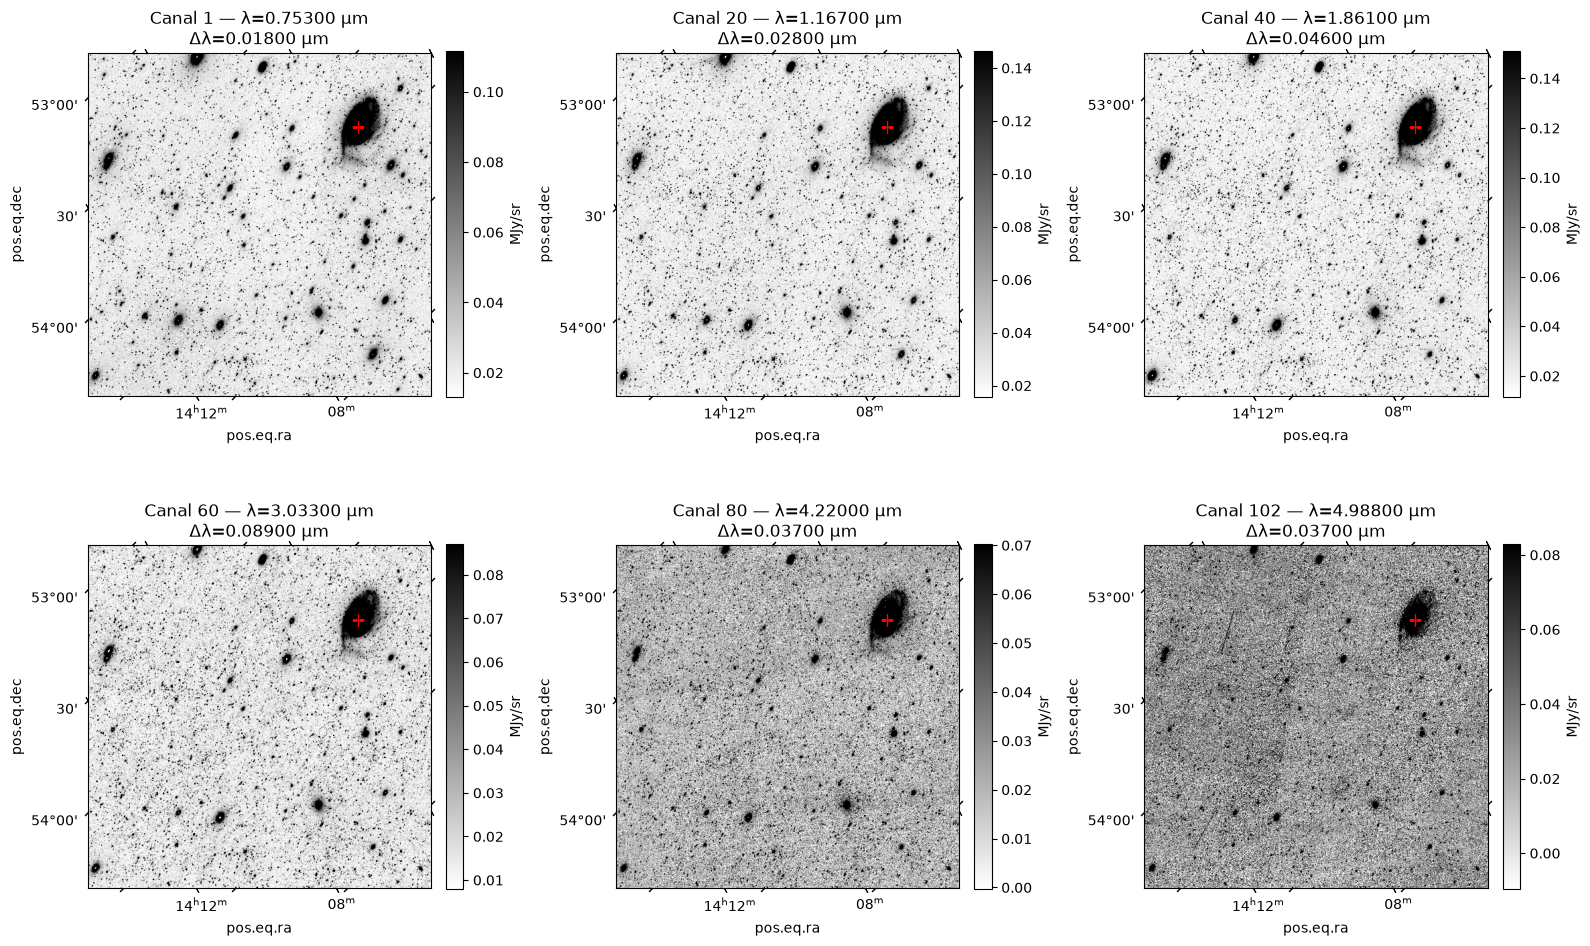

In [6]:
cubo_muestra = cubo_original[INDICES].copy()
tabla_muestra = espectral_102[INDICES].copy()
tabla_muestra["brillo_M101"] = cubo_original[INDICES, y_m101, x_m101] * u.Unit(unidad_brillo)
if flags_original is not None:
    tabla_muestra["flags_M101"] = flags_original[INDICES, y_m101, x_m101]
if nhits_original is not None:
    tabla_muestra["nhits_M101"] = nhits_original[INDICES, y_m101, x_m101]
print("Dimensiones de la muestra:", cubo_muestra.shape)
display(tabla_muestra)

fig, ejes = plt.subplots(2, 3, figsize=(16, 10), subplot_kw={"projection": wcs_original})
for i, ax in enumerate(ejes.flat):
    imagen = cubo_muestra[i]
    validos = imagen[np.isfinite(imagen)]
    vmin, vmax = np.percentile(validos, [3.5, 96.5]) if validos.size else (0, 1)
    im = ax.imshow(imagen, origin="lower", cmap="gray_r", vmin=vmin, vmax=vmax)
    ax.plot(x_m101, y_m101, "+", color="red", markersize=8)
    ancho = anchos[INDICES[i]]
    texto = f"Δλ={ancho:.5f} µm" if np.isfinite(ancho) else "Δλ no disponible"
    ax.set_title(f"Canal {CANALES[i]} — λ={centros[INDICES[i]]:.5f} µm\n{texto}")
    fig.colorbar(im, ax=ax, label=unidad_brillo, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 5. Imprimir el cubo original de 102 canales

La siguiente celda imprime el array original. NumPy abrevia la salida mediante `...` para evitar millones de valores en Jupyter; los **102 canales permanecen íntegros en memoria**. La celda opcional posterior imprime literalmente todos los valores, sin abreviar, y puede producir una salida enorme.


In [7]:
print("Dimensiones (canal, y, x):", cubo_original.shape)
print(cubo_original)


Dimensiones (canal, y, x): (102, 512, 512)
[[[ 0.03138588  0.02067737  0.01791353 ...  0.02321928  0.02070154
    0.02118911]
  [ 0.02183309  0.02326078  0.01465331 ...  0.01697266  0.02094328
    0.02093746]
  [ 0.01477986  0.01613951  0.02690175 ...  0.02929492  0.01511146
    0.01291475]
  ...
  [ 0.01874677  0.01586565  0.02842598 ...  0.01630878  0.02511647
    0.03218209]
  [ 0.01771786  0.02462852  0.03192598 ...  0.03451411  0.02426387
    0.0270867 ]
  [ 0.01608454  0.02033639  0.02595421 ...  0.021246    0.02586656
    0.01906776]]

 [[ 0.03466694  0.02631794  0.02755806 ...  0.02022278  0.02598266
    0.02058562]
  [ 0.03388604  0.01758401  0.02856139 ...  0.01481583  0.02140764
    0.01704304]
  [ 0.02432427  0.01797152  0.0261706  ...  0.02546982  0.01865715
    0.01806294]
  ...
  [ 0.02782203  0.02420753  0.01866826 ...  0.0236094   0.03094282
    0.03486409]
  [ 0.01327014  0.02432677  0.03230545 ...  0.04215511  0.02040925
    0.04173518]
  [ 0.0191453   0.02321996  0.

## 6. Plan de acción si falla la consulta o la interpretación

1. **Entorno:** comprobar que el kernel importa Astroquery y Astropy; instalar las dependencias con `%pip` en ese mismo kernel y reiniciarlo si hace falta.
2. **Conexión a IRSA:** si falla SIA2 o su endpoint de capacidades, comprobar la conexión y el servicio; repetir únicamente la consulta de la sección 1. No interpretar una falla de red como ausencia de datos.
3. **Identificación del producto:** revisar `results`, `url_original` y `hdul.info()`; confirmar colección `spherex_dr1_cube`, IMAGE con 102 planos y SPECTRAL_CHANNELS con 102 filas.
4. **Coordenadas y cobertura:** verificar la WCS y el píxel de M101. Si hay varias teselas, inspeccionar las candidatas; si se necesita toda la extensión de M101, definir tamaño angular y construir un mosaico con sus solapamientos.
5. **Esquema espectral:** compartir los nombres y unidades de `tabla_espectral` y las columnas FITS. Configurar `COLUMNAS` con los nombres reales; comprobar que la numeración coincide con el orden de los planos. No inventar longitudes de onda ni anchos.
6. **Calidad:** inspeccionar FLAGS y NHITS y los valores no finitos del píxel. Consultar las definiciones oficiales antes de decidir qué bits excluir. Los canales vacíos del producto se mantienen como tales.
7. **Memoria y salida:** si falla la carga, leer planos por secciones FITS o trabajar desde disco. Si Jupyter se vuelve lento al imprimir, usar la impresión abreviada; no cambia los datos en `cubo_original`.

Al reportar un problema, incluir la sección, el mensaje de error completo y el esquema FITS, para definir el siguiente ajuste con evidencia.


/tmp/ipykernel_43522/429800964.py:32: UserWarning: Canales sin datos finitos en la malla (transparentes): [51, 52]
  warnings.warn(f"Canales sin datos finitos en la malla (transparentes): {canales_vacios_3d.tolist()}")


Cubo original: (102, 512, 512); malla dibujada: (102, 32, 32).
Escala de color común: percentiles 3.5–96.5; los valores originales se conservan.


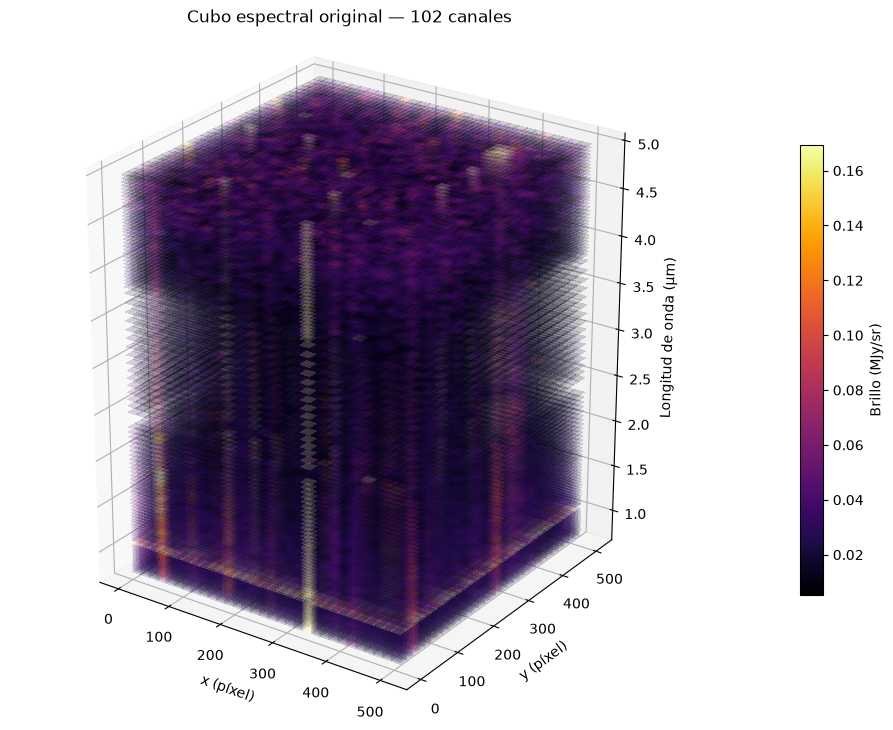

In [8]:
# Último paso: visualizar las matrices de los 102 canales como cubo espectral 3D.
# Los ejes son x, y y longitud de onda; el color representa el brillo original.
# La tercera dimensión es espectral, no una distancia física a la galaxia.
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

if "cubo_original" not in globals() or "centros" not in globals():
    raise RuntimeError("Ejecuta primero las celdas de carga del cubo y de interpretación espectral.")
if cubo_original.ndim != 3 or cubo_original.shape[0] != 102:
    raise ValueError(f"Se esperaba un cubo (102, y, x); se recibió {cubo_original.shape}.")
longitudes_3d = np.asarray(centros, dtype=float)
if (longitudes_3d.shape != (102,) or not np.all(np.isfinite(longitudes_3d))
        or not np.all(np.diff(longitudes_3d) > 0)):
    raise ValueError("Las 102 longitudes de onda deben ser finitas y estar en orden creciente.")
_, alto_3d, ancho_3d = cubo_original.shape
if min(alto_3d, ancho_3d) < 2:
    raise ValueError("Cada matriz necesita al menos dos filas y dos columnas para dibujar superficies.")

# Hasta 32 muestras por eje espacial para mantener manejables las 102 superficies.
# Se incluyen los bordes y se mantienen todos los canales, sin modificar el cubo.
xs_3d = np.unique(np.linspace(0, ancho_3d - 1, min(32, ancho_3d), dtype=int))
ys_3d = np.unique(np.linspace(0, alto_3d - 1, min(32, alto_3d), dtype=int))
vista_3d = cubo_original[:, ys_3d[:, None], xs_3d]
validos_3d = vista_3d[np.isfinite(vista_3d)]
if not validos_3d.size:
    raise ValueError("No hay brillo finito en la malla de visualización; revisa los datos o aumenta el muestreo.")
canales_vacios_3d = np.flatnonzero(~np.isfinite(vista_3d).any(axis=(1, 2))) + 1
if canales_vacios_3d.size:
    warnings.warn(f"Canales sin datos finitos en la malla (transparentes): {canales_vacios_3d.tolist()}")
vmin_3d, vmax_3d = np.percentile(validos_3d, [3.5, 96.5])
if vmin_3d == vmax_3d:
    margen_3d = max(abs(float(vmin_3d)) * 0.01, 1e-6)
    vmin_3d, vmax_3d = vmin_3d - margen_3d, vmax_3d + margen_3d
norma_3d = Normalize(vmin=vmin_3d, vmax=vmax_3d, clip=True)
mapa_3d = plt.get_cmap("inferno")
xx_3d, yy_3d = np.meshgrid(xs_3d, ys_3d)
fig_cubo_3d = plt.figure(figsize=(12, 9))
ax_cubo_3d = fig_cubo_3d.add_subplot(111, projection="3d")
for indice_3d, longitud_3d in enumerate(longitudes_3d):
    plano_3d = vista_3d[indice_3d]
    colores_3d = mapa_3d(norma_3d(np.ma.masked_invalid(plano_3d)))
    colores_3d[..., 3] = np.where(np.isfinite(plano_3d), 0.18, 0.0)
    ax_cubo_3d.plot_surface(
        xx_3d, yy_3d, np.full(xx_3d.shape, longitud_3d),
        facecolors=colores_3d, rstride=1, cstride=1,
        linewidth=0, antialiased=False, shade=False,
    )
ax_cubo_3d.set(xlabel="x (píxel)", ylabel="y (píxel)",
               zlabel="Longitud de onda (µm)",
               title="Cubo espectral original — 102 canales")
ax_cubo_3d.set_box_aspect((1, 1, 1.2))
ax_cubo_3d.view_init(elev=25, azim=-55)
fig_cubo_3d.colorbar(
    ScalarMappable(norm=norma_3d, cmap=mapa_3d), ax=ax_cubo_3d,
    shrink=0.65, pad=0.12, label=f"Brillo ({unidad_brillo})",
)
print(f"Cubo original: {cubo_original.shape}; malla dibujada: {vista_3d.shape}.")
print("Escala de color común: percentiles 3.5–96.5; los valores originales se conservan.")
plt.show()
